# Analyse Exploratoire

### Import des modules

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

### Analyse Exploratoire
#### importation du dataset
Importer le dataset dans une variable qui sera utilisée a plusieurs reprises durant ce projet

In [4]:
building_consumption = pd.read_csv("data/raw/2016_Building_Energy_Benchmarking.csv")

Ici c'est pour verifier que le dataset est bien importé et avoir une premiere vue des données

In [5]:
building_consumption

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,...,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,...,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,...,5.252517e+05,1.792159e+06,39737.390630,3.973739e+06,False,NaN,Compliant,NaN,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,South Park Community Center,8319 8th Ave S,Seattle,WA,NaN,7883603155,...,1.022480e+05,3.488702e+05,3706.010010,3.706010e+05,False,NaN,Compliant,NaN,22.11,1.57


#### Audit du dataset 

Vue d'ensemble

In [ ]:
# les dimensions (nb lignes , nb colonnes)
building_consumption.shape

In [ ]:
# Les informations générales sur le dataset , permet aussi de voir ou sont les valeurs nulles
# En comparant le nb de lignes et les non-null 
building_consumption.info()

In [ ]:
# Description détaillée de chaque colonne 
building_consumption.describe(include="all")

#### Création du dataset 'Allégé'
L'intérêt est de créer un dataset personnalisé et plus léger pour permettre un meilleure exploration des données

Suppression des lignes de type résidentiel

In [ ]:
#Identification de toutes les lignes de type résidential 
building_consumption['BuildingType'].value_counts()

In [6]:
#  Liste des types de bâtiments à exclure
multifamily_types = [
    'Multifamily LR (1-4)', 
    'Multifamily MR (5-9)', 
    'Multifamily HR (10+)'
]

# Filtrer pour ne garder que les lignes qui NE SONT PAS dans cette liste
building_consumption_no_residential = building_consumption[~building_consumption['BuildingType'].isin(multifamily_types)]

Verification que le nouveau dataframe est bien réduit en nombre de lignes

In [106]:
building_consumption_no_residential.shape

(1668, 46)

Les lignes de type résidentiel ont été supprimées
Le nombre de ligne total du dataset était de 3776 et est passé a 1668

Suppression des colonnes (variables) qui ne sont pas nécessaire a l'analyse de données et au ML 


<table style="width: 100%; border-collapse: collapse; border: none;">
  <tr>
    <td style="vertical-align: top; width: 32%; padding-right: 15px; border: none;">
      <table border="1" style="width: 100%; border-collapse: collapse;">
        <thead>
          <tr>
            <th style="padding: 8px; text-align: left;">Colonnes</th>
          </tr>
        </thead>
        <tbody>
          <tr><td style="padding: 6px;">YearBuilt</td></tr>
          <tr><td style="padding: 6px;">NumberofBuildings</td></tr>
          <tr><td style="padding: 6px;">NumberofFloors</td></tr>
          <tr><td style="padding: 6px;">PropertyGFATotal</td></tr>
          <tr><td style="padding: 6px;">PropertyGFAParking</td></tr>
          <tr><td style="padding: 6px;">PropertyGFABuilding(s)</td></tr>
          <tr><td style="padding: 6px;">ListOfAllPropertyUseTypes</td></tr>
          <tr><td style="padding: 6px;">SiteEUI(kBtu/sf)</td></tr>
          <tr><td style="padding: 6px;">SiteEnergyUse(kBtu)</td></tr>
          <tr><td style="padding: 6px;">SteamUse(kBtu)</td></tr>
          <tr><td style="padding: 6px;">Electricity(kBtu)</td></tr>
          <tr><td style="padding: 6px;">NaturalGas(kBtu)</td></tr>
          <tr><td style="padding: 6px;">DefaultData</td></tr>
          <tr><td style="padding: 6px;">ComplianceStatus</td></tr>
          <tr><td style="padding: 6px;">TotalGHGEmissions</td></tr>
        </tbody>
      </table>
    </td>
    <td style="vertical-align: top; width: 68%; border: none;">
      <table border="1" style="width: 100%; border-collapse: collapse;">
        <thead>
          <tr>
            <th style="padding: 8px; text-align: left;">À supprimer</th>
            <th style="padding: 8px; text-align: left;">Justification</th>
          </tr>
        </thead>
        <tbody>
          <tr>
            <td style="padding: 6px;">OSEBuildingID</td>
            <td style="padding: 6px;">L’identifiant unique n'est pas pertinent à garder car nous ne souhaitons pas identifier un batiment en particulier</td>
          </tr>
          <tr>
            <td style="padding: 6px;">DataYear</td>
            <td style="padding: 6px;">Pas utile<br>Toutes les lignes ont la même année : 2016<br><code>building_consumption['DataYear'].value_counts(dropna=False)</code></td>
          </tr>
          <tr>
            <td style="padding: 6px;">BuildingType</td>
            <td style="padding: 6px;">Pas utile à garder pour l'analyse mais nécessaire pour filtrer les habitations pour ne pas les traiter</td>
          </tr>
          <tr>
            <td style="padding: 6px;">PrimaryPropertyType</td>
            <td style="padding: 6px;">Pas nécessaire de les garder car la variable <code>ListOfAllPropertyUseTypes</code> le fait aussi et en mieux</td>
          </tr>
          <tr>
            <td style="padding: 6px;">PropertyName</td>
            <td style="padding: 6px;">Pas nécessaire car pas besoin d'identifier un batiment en particulier</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Address</td>
            <td style="padding: 6px;">Pas besoin de cette information pour l'analyse</td>
          </tr>
          <tr>
            <td style="padding: 6px;">City</td>
            <td style="padding: 6px;">Pas utile<br>Toutes les lignes ont la même année : Seattle<br><code>building_consumption['City'].value_counts(dropna=False)</code></td>
          </tr>
          <tr>
            <td style="padding: 6px;">State</td>
            <td style="padding: 6px;">Pas utile<br>Toutes les lignes ont la même année : WA<br><code>building_consumption['City'].value_counts(dropna=False)</code></td>
          </tr>
          <tr>
            <td style="padding: 6px;">ZipCode</td>
            <td style="padding: 6px;">Pas utile<br>Nous ne cherchons pas a savoir ou le batiment se situe (Seattle est suffisant)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">TaxParcelIdentificationNumber</td>
            <td style="padding: 6px;">Pas utile (tout comme l'identifiant unique)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">CouncilDistrictCode</td>
            <td style="padding: 6px;">Pas utile<br>Nous ne cherchons pas a savoir ou le batiment se situe (Seattle est suffisant)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Neighborhood</td>
            <td style="padding: 6px;">Pas utile<br>Nous ne cherchons pas a savoir ou le batiment se situe (Seattle est suffisant)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Latitude</td>
            <td style="padding: 6px;">Pas utile<br>Nous ne cherchons pas a savoir ou le batiment se situe (Seattle est suffisant)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Longitude</td>
            <td style="padding: 6px;">Pas utile<br>Nous ne cherchons pas a savoir ou le batiment se situe (Seattle est suffisant)</td>
          </tr>
          <tr>
            <td style="padding: 6px;">LargestPropertyUseType</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">LargestPropertyUseTypeGFA</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SecondLargestPropertyUseType</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SecondLargestPropertyUseTypeGFA</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">ThirdLargestPropertyUseType</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">ThirdLargestPropertyUseTypeGFA</td>
            <td style="padding: 6px;">Les surfaces de chaque type d'utilisation n'est pas nécessaire</td>
          </tr>
          <tr>
            <td style="padding: 6px;">YearsENERGYSTARCertified</td>
            <td style="padding: 6px;">Pas utile</td>
          </tr>
          <tr>
            <td style="padding: 6px;">ENERGYSTARScore</td>
            <td style="padding: 6px;">Pas utile</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SiteEUIWN(kBtu/sf)</td>
            <td style="padding: 6px;">Pas utile<br>La ligne SiteEUI(kBtu/sf) donne un résultat plus pertinent</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SourceEUI(kBtu/sf)</td>
            <td style="padding: 6px;">Pas utile , nous voulons savoir quelle energie consommée et non a la source</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SourceEUIWN(kBtu/sf)</td>
            <td style="padding: 6px;">Pas utile , nous voulons savoir quelle energie consommée et non a la source</td>
          </tr>
          <tr>
            <td style="padding: 6px;">SiteEnergyUseWN(kBtu)</td>
            <td style="padding: 6px;">Pas utile , nous voulons savoir quelle energie consommée et non a la source</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Electricity(kWh)</td>
            <td style="padding: 6px;">Pas utile , la variable Electricity(kBtu) donne la meme information avec la bonne unité de mesure</td>
          </tr>
          <tr>
            <td style="padding: 6px;">NaturalGas(therms)</td>
            <td style="padding: 6px;">Pas utile , la variable NaturalGas(kBtu) donne la meme information avec la bonne unité de mesure</td>
          </tr>
          <tr>
            <td style="padding: 6px;">Comments</td>
            <td style="padding: 6px;">Pas utile car toutes vides<br><code>building_consumption['Comments'].value_counts(dropna=False)</code></td>
          </tr>
          <tr>
            <td style="padding: 6px;">Outlier</td>
            <td style="padding: 6px;">Pas exploitable car presque toutes vides <br><code>building_consumption['Outlier'].value_counts(dropna=False)</code></td>
          </tr>
          <tr>
            <td style="padding: 6px;">GHGEmissionsIntensity</td>
            <td style="padding: 6px;">Pas utile car nous mesurons le total et pas l'intensité des emission de gaz a effet de serre</td>
          </tr>
        </tbody>
      </table>
    </td>
  </tr>
</table>


In [8]:
#  Création d'un nouveau dataset 'copie' pour ne pas travailler sur l'original
building_consumption_light = building_consumption_no_residential

#  Suppression des colonnes qui ne seront pas nécessaire a l'anayse exploratoire et au Machine Learning
building_consumption_light = building_consumption_light.drop([
                                                        'OSEBuildingID',
                                                        'DataYear',
                                                        'BuildingType',
                                                        'PrimaryPropertyType',
                                                        'PropertyName',
                                                        'Address',
                                                        'City',
                                                        'State',
                                                        'ZipCode',
                                                        'TaxParcelIdentificationNumber',
                                                        'CouncilDistrictCode',
                                                        'Neighborhood',
                                                        'Latitude',
                                                        'Longitude',
                                                        'LargestPropertyUseType',
                                                        'LargestPropertyUseTypeGFA',
                                                        'SecondLargestPropertyUseType',
                                                        'SecondLargestPropertyUseTypeGFA',
                                                        'ThirdLargestPropertyUseType',
                                                        'ThirdLargestPropertyUseTypeGFA',
                                                        'YearsENERGYSTARCertified',
                                                        'ENERGYSTARScore',
                                                        'SiteEUIWN(kBtu/sf)',
                                                        'SourceEUI(kBtu/sf)',
                                                        'SourceEUIWN(kBtu/sf)',
                                                        'SiteEnergyUseWN(kBtu)',
                                                        'Electricity(kWh)',
                                                        'NaturalGas(therms)',
                                                        'Outlier',
                                                        'Comments',
                                                        'GHGEmissionsIntensity'], axis=1)


Verification que les colonnes n'apparaissent pas dans le nouveau dataset 

In [9]:
building_consumption_light.shape

(1668, 15)

Comme nous avons supprimé plusieurs colonnes , le dataSet change de dimensions pour passer de (3376 :46) à (1668 : 15)

#### Detection des nulls sur la distribution allégée

In [108]:
df_nulls_light = building_consumption_light.isna().sum().reset_index()
df_nulls_light.columns = ["variable", "nb_nulls"]
df_nulls_light['Frequence'] = df_nulls_light['nb_nulls'] / len(building_consumption_light)
df_nulls_light = df_nulls_light.sort_values('Frequence', ascending=False)
df_nulls_light


,variable,nb_nulls,Frequence
0,YearBuilt,0,0.0
1,NumberofBuildings,0,0.0
2,NumberofFloors,0,0.0
3,PropertyGFATotal,0,0.0
4,PropertyGFAParking,0,0.0
5,PropertyGFABuilding(s),0,0.0
6,ListOfAllPropertyUseTypes,0,0.0
7,SiteEUI(kBtu/sf),0,0.0
8,SiteEnergyUse(kBtu),0,0.0
9,SteamUse(kBtu),0,0.0


Les fréquences des valeurs nulles sur les variables du dataset allégé sont très faibles.  
Il s'agit en moyenne de 2 cas sur 1600

Bonne pratique :  
Moins de 1 % (moins de 0.1) de nulls : suppression, sans se poser de questions.  
Entre 1 et 30 % (entre 0.1 et 0.3): imputation, selon l’importance de la variable.  
Plus de 50 % (plus de 0.5): souvent, on supprime la colonne entière.  

#### Verification des lignes concernées par les nulls 

In [14]:
building_consumption_light.loc[building_consumption_light["SiteEUI(kBtu/sf)"].isna()]

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions
304,1990,1.0,6,1400000,0,1400000,"Convention Center, Parking",NaN,0.0,0.0,0.0,0.0,False,Non-Compliant,0.0
578,1924,NaN,4,63150,0,63150,NaN,NaN,NaN,NaN,NaN,NaN,False,Non-Compliant,NaN
2670,1928,NaN,2,20760,0,20760,NaN,NaN,NaN,NaN,NaN,NaN,False,Non-Compliant,NaN


Avec cette commande , je constate que l'intégralité des 17 valeurs nulles sont réparties sur 3 lignes 

Notemment sur les colonnes NumberofBuildings, ListOfAllPropertyUseTypes, SiteEUI(kBtu/sf), SiteEnergyUse(kBtu), SteamUse(kBtu), Electricity(kBtu), NaturalGas(kBtu), TotalGHGEmissions. 

Chaque valeur null  ne concerne que moins de 1% des valeurs du dataset. On peut donc les supprimer sans qu'elles aient un impact significatif sur les données.

#### Suppression des lignes avec des valeurs nulles et verification

In [11]:
building_consumption_light = building_consumption_light.dropna(subset=['SiteEUI(kBtu/sf)'])

In [12]:
df_sans_nulls = building_consumption_light.isna().sum().reset_index()
df_sans_nulls.columns = ["variable", "nb_nulls"]
df_sans_nulls

,variable,nb_nulls
0,YearBuilt,0
1,NumberofBuildings,0
2,NumberofFloors,0
3,PropertyGFATotal,0
4,PropertyGFAParking,0
5,PropertyGFABuilding(s),0
6,ListOfAllPropertyUseTypes,0
7,SiteEUI(kBtu/sf),0
8,SiteEnergyUse(kBtu),0
9,SteamUse(kBtu),0


#### Detection des valeurs aberrantes sur la distribution allégée

tracer l'obeservation graphique 

Si 2 variables quantitatives >> nuage de point.  
Si qualitatives et quantitatives >> boxplots anova ou kurskal wallis.  
si qualitatives >> tableau de conteingence (tableau croisé) >> Khi 2 ou V cramer.   

Pour tracer ces graphs il faut dans un premier temps isoler les variables quantitatives.   
En créeant ,un dataframe dédié pour ne traiter que les variables FLOAT et INT   


In [67]:
# Lister les variables et le type 
building_consumption_light.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1665 entries, 0 to 3375
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   YearBuilt                  1665 non-null   int64  
 1   NumberofBuildings          1665 non-null   float64
 2   NumberofFloors             1665 non-null   int64  
 3   PropertyGFATotal           1665 non-null   int64  
 4   PropertyGFAParking         1665 non-null   int64  
 5   PropertyGFABuilding(s)     1665 non-null   int64  
 6   ListOfAllPropertyUseTypes  1665 non-null   object 
 7   SiteEUI(kBtu/sf)           1665 non-null   float64
 8   SiteEnergyUse(kBtu)        1665 non-null   float64
 9   SteamUse(kBtu)             1665 non-null   float64
 10  Electricity(kBtu)          1665 non-null   float64
 11  NaturalGas(kBtu)           1665 non-null   float64
 12  DefaultData                1665 non-null   bool   
 13  ComplianceStatus           1665 non-null   object 
 1

In [68]:
liste_variables_numeriques = building_consumption_light.select_dtypes(include="number").columns
liste_variables_numeriques

Index(['YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal',
       'PropertyGFAParking', 'PropertyGFABuilding(s)', 'SiteEUI(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)',
       'NaturalGas(kBtu)', 'TotalGHGEmissions'],
      dtype='object')

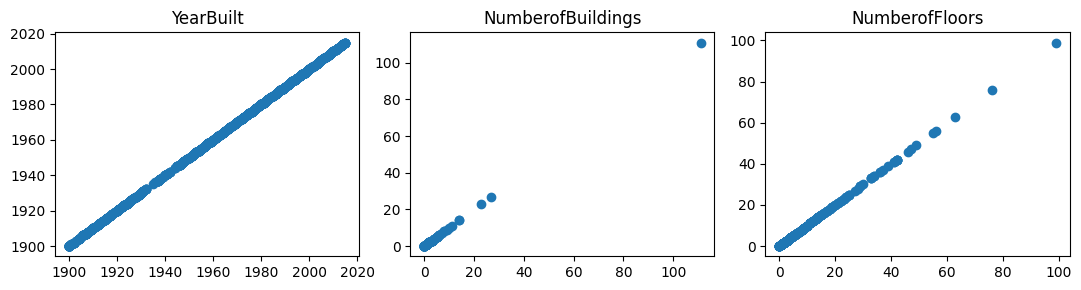

In [103]:
plt.figure(figsize= (18, 3))

plt.subplot(1, 5, 1)
plt.scatter(building_consumption_light['YearBuilt'].values, building_consumption_light['YearBuilt'])
plt.title("YearBuilt")
plt.subplot(1, 5, 2)
plt.scatter(building_consumption_light['NumberofBuildings'].values, building_consumption_light['NumberofBuildings'])
plt.title("NumberofBuildings")
plt.subplot(1, 5, 3)
plt.scatter(building_consumption_light['NumberofFloors'].values, building_consumption_light['NumberofFloors'])
plt.title("NumberofFloors")
plt.tight_layout()
plt.show()


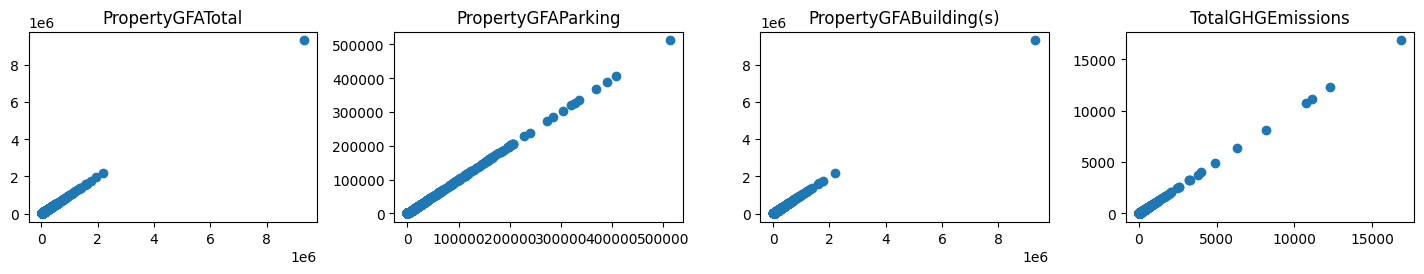

In [111]:
plt.figure(figsize= (18, 3))

plt.subplot(1, 5, 1)
plt.scatter(building_consumption_light['PropertyGFATotal'].values, building_consumption_light['PropertyGFATotal'])
plt.title("PropertyGFATotal")
plt.subplot(1, 5, 2)
plt.scatter(building_consumption_light['PropertyGFAParking'].values, building_consumption_light['PropertyGFAParking'])
plt.title("PropertyGFAParking")
plt.subplot(1, 5, 3)
plt.scatter(building_consumption_light['PropertyGFABuilding(s)'].values, building_consumption_light['PropertyGFABuilding(s)'])
plt.title("PropertyGFABuilding(s)")
plt.subplot(1, 5, 4)
plt.scatter(building_consumption_light['TotalGHGEmissions'].values, building_consumption_light['TotalGHGEmissions'])
plt.title("TotalGHGEmissions")

plt.tight_layout()
plt.show()

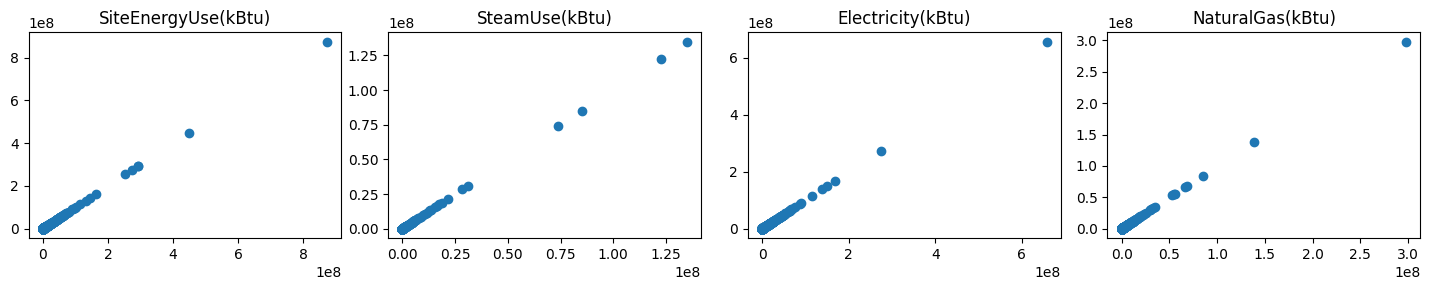

In [110]:
plt.figure(figsize= (18, 3))

plt.subplot(1, 5, 1)
plt.scatter(building_consumption_light['SiteEnergyUse(kBtu)'].values, building_consumption_light['SiteEnergyUse(kBtu)'])
plt.title("SiteEnergyUse(kBtu)")
plt.subplot(1, 5, 2)
plt.scatter(building_consumption_light['SteamUse(kBtu)'].values, building_consumption_light['SteamUse(kBtu)'])
plt.title("SteamUse(kBtu)")
plt.subplot(1, 5, 3)
plt.scatter(building_consumption_light['Electricity(kBtu)'].values, building_consumption_light['Electricity(kBtu)'])
plt.title("Electricity(kBtu)")
plt.subplot(1, 5, 4)
plt.scatter(building_consumption_light['NaturalGas(kBtu)'].values, building_consumption_light['NaturalGas(kBtu)'])
plt.title("NaturalGas(kBtu)")

plt.tight_layout()
plt.show()

INTERPRETATION :   
Avec les scatterplot, nous avons un visuel des valeurs de chaque colonnes quantitatives.  
Maintenant, si on observe les variables NumberofBuildings, PropertyGFATotal, et autres, nous constatons bien que les valeurs sont très regroupées (sauf une seule) 
Nous constatons que la variable YearBuilt ne présente pas de valeurs trop éloignées des autres.  
    
Ensuite nous pouvons utiliser voir quelles sont les variables abarrantes en utilisant la methode de l'IQR sur chaque colonne en utilsant une boucle


In [ ]:
# On crée 2 listes qui ont pour but de stocker les résultats des valeurs abérrantes et extremes de chaque colonne
# On boucle sur chaque colonne pour calculer Q1 et Q3, ensuite l'IQR et enfin les bornes (basse et hautes)
# Pour identifier les valeurs aberrantes : on teste si la valeur est inférieure a la borne basse ou supérieue a la bonre haute
# on stocke enfin le résultat sous forne de dictionnaire (clé : valeur) dans la liste des résultats


liste_nb_aberrantes = []
liste_nb_extremes = []

for col in liste_variables_numeriques:
    # Calcul Q1, Q3 et IQR
    q1 = building_consumption_light[col].quantile(0.25)
    q3 = building_consumption_light[col].quantile(0.75)
    iqr = q3 - q1

    # Calcul des bornes basses et hautes 
    borne_basse = q1 - (1.5 * iqr)
    borne_haute = q3 + (1.5 * iqr)

    # Calcul des bornes basses et hautes extremes
    borne_basse_extreme = q1 - (3 * iqr)
    borne_haute_extreme = q3 + (3 * iqr)

    # Test si inférieur a la borne basse OU supérieur a la borne haute >> si True alors on le stocke dans nb
    nb_aberrantes = ((building_consumption_light[col] < borne_basse) | (building_consumption_light[col] > borne_haute)).sum()
    # nb_aberrantes = ((building_consumption_light[col] > borne_haute)).sum()
    nb_extremes = ((building_consumption_light[col] < borne_basse_extreme) | (building_consumption_light[col] > borne_haute_extreme)).sum()

    # on ajoute la variable nb a la liste
    liste_nb_aberrantes.append({"variable": col, "nb_aberrantes": nb_aberrantes, "nb_extremes" : nb_extremes})

# Création d'un dataframe pour afficher les résultats
df_valeurs_aberrantes = pd.DataFrame(liste_nb_aberrantes)
df_valeurs_aberrantes

,variable,nb_aberrantes,nb_extremes
0,YearBuilt,0,0
1,NumberofBuildings,105,105
2,NumberofFloors,138,78
3,PropertyGFATotal,202,120
4,PropertyGFAParking,333,333
5,PropertyGFABuilding(s),181,111
6,SiteEUI(kBtu/sf),159,77
7,SiteEnergyUse(kBtu),188,114
8,SteamUse(kBtu),114,114
9,Electricity(kBtu),193,118


Etant donné le nombre de valeurs aberrantes trouvées dans ces variables (ca peut etre normal car la distribution n'est peut-etre pas symétrique)

In [71]:
building_consumption_light[liste_variables_numeriques].describe().round(0)

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
count,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0,1665.0
mean,1962.0,1.0,4.0,118166.0,12921.0,105244.0,72.0,8443001.0,512880.0,5847002.0,1972028.0,185.0
std,33.0,3.0,7.0,295955.0,42309.0,282683.0,74.0,30252182.0,5515586.0,20802480.0,9373504.0,752.0
min,1900.0,0.0,0.0,11285.0,0.0,3636.0,0.0,0.0,0.0,-115417.0,0.0,-1.0
25%,1930.0,1.0,1.0,29498.0,0.0,28492.0,34.0,1232823.0,0.0,722467.0,0.0,20.0
50%,1965.0,1.0,2.0,49280.0,0.0,47368.0,52.0,2556131.0,0.0,1612547.0,499509.0,50.0
75%,1989.0,1.0,4.0,105100.0,0.0,94713.0,82.0,6917280.0,0.0,4855036.0,1522434.0,142.0
max,2015.0,111.0,99.0,9320156.0,512608.0,9320156.0,834.0,873923712.0,134943456.0,657074389.0,297909000.0,16871.0


In [ ]:
df_min_max = building_consumption_light[liste_variables_numeriques].describe().T[["min", "max"]].round(0)


,min,max
YearBuilt,1900.0,2015.0
NumberofBuildings,0.0,111.0
NumberofFloors,0.0,99.0
PropertyGFATotal,11285.0,9320156.0
PropertyGFAParking,0.0,512608.0
PropertyGFABuilding(s),3636.0,9320156.0
SiteEUI(kBtu/sf),0.0,834.0
SiteEnergyUse(kBtu),0.0,873923712.0
SteamUse(kBtu),0.0,134943456.0
Electricity(kBtu),-115417.0,657074389.0


Ce qui doit etre etudié : 
* NumberofBuildings.   
  0  Ce n'est pas possible.   
  110  On doit le garder , il s'agit de l'université de Seattle
                     
* NumberofFloors.  
  0  Ce n'est pas possible.  
  99  Aucun batiment a Seattle ne fait 99 etages. (a supprimer)

* TotalGHGEmissions.  
  -1  pas possible d'avoir un total négatif

* Electricity(kBtu).   
  -115417.0  Une consommation en élécticité négative n'est pas possible

* SiteEnergyUse(kBtu) et SiteEUI(kBtu/sf).   
  Valeur min = 0 sont probablement des valeur manquantes (a calculer)


calcul du nombre de lignes concernées

In [ ]:
print(f"Electricity(kBtu) est inférieur a O: ",(building_consumption_light["Electricity(kBtu)"] < 0).sum())
print(f"TotalGHGEmissions est inférieur a O: ",(building_consumption_light["TotalGHGEmissions"] < 0).sum())
print(f"NumberofBuildings est égal a O: ",(building_consumption_light["NumberofBuildings"] == 0).sum())
print(f"NumberofFloors est égal a O: ",(building_consumption_light["NumberofFloors"] == 0).sum())
print(f"SiteEnergyUse(kBtu) est égal a O: ",(building_consumption_light["SiteEnergyUse(kBtu)"] == 0).sum())
print(f"SiteEUI(kBtu/sf) est égal a O: ",(building_consumption_light["SiteEUI(kBtu/sf)"] == 0).sum())

#### Traitement de Electricity(kBtu) en valeure négative.  
Identification de la ligne concernée

In [ ]:
building_consumption_light.loc[building_consumption_light['Electricity(kBtu)'] < 0]

En sachant que SiteEnergyUse(kBtu)   =   SteamUse(kBtu) + Electricity(kBtu) + NaturalGas(kBtu)
En isolant la ligne concernée , on constate que ni SteamUse, ni NaturalGas sont renseignés

Il n'y a qu'une seule ligne concernée, on la supprime 
L'argument inplace= True sert a modifier directement le dataframe actuel (pas forcément conseillé)

In [ ]:
building_consumption_light.drop(building_consumption_light[building_consumption_light['Electricity(kBtu)'] < 0].index, inplace= True)

En supprimant la ligne avec Electricity(kBtu), on a également supprimé l'autre valeur négative sur la variable TotalGHGEmissions

#### Traitement des valeurs de SiteEnergyUse(kBtu) et SiteEUI(kBtu/sf)
Identification des lignes concernées

In [119]:
building_consumption_light.loc[(building_consumption_light['SiteEUI(kBtu/sf)'] == 0) | (building_consumption_light['SiteEnergyUse(kBtu)'] == 0)]


,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions
28,1955,1.0,1,126351,0,126351,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.00
31,1989,1.0,2,51582,0,51582,K-12 School,0.0,0.0,0.0,1496816.0,0.0,False,Missing Data,10.43
62,1948,1.0,2,53352,0,53352,K-12 School,0.0,0.0,0.0,600813.0,0.0,False,Missing Data,4.19
81,1999,1.0,3,74468,0,74468,K-12 School,0.0,0.0,0.0,1698176.0,0.0,False,Missing Data,11.84
85,1991,1.0,2,58933,0,58933,K-12 School,0.0,0.0,0.0,2347138.0,0.0,False,Missing Data,16.36
95,1991,1.0,3,66588,0,66588,K-12 School,0.0,0.0,0.0,2104286.0,0.0,False,Missing Data,14.67
133,1959,1.0,1,160270,0,160270,K-12 School,0.0,0.0,0.0,0.0,4318917.0,False,Missing Data,229.38
139,1963,1.0,3,136188,0,136188,K-12 School,0.0,0.0,0.0,0.0,3217877.0,False,Missing Data,170.90
152,1989,1.0,2,52792,0,52792,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.00
614,1988,1.0,1,52924,0,52924,K-12 School,0.0,0.0,0.0,1957268.0,0.0,False,Missing Data,13.64


#### Les variables relationnelles

Nous pouvons constater qu'il y a une relation entre les variables 
* SiteEnergyUse(kBtu)   =   SteamUse(kBtu) + Electricity(kBtu) + NaturalGas(kBtu).  
* PropertyGFATotal   =   PropertyGFAParking + PropertyGFABuilding(s). 
* SiteEUI(kBtu/sf) = SiteEnergyUse(kBtu) / PropertyGFATotal.   


Verification des relations entre les variables.  
SiteEnergyUse(kBtu)   =   SteamUse(kBtu) + Electricity(kBtu) + NaturalGas(kBtu)

In [ ]:
df = building_consumption_light
masque_non_nul = df['SiteEnergyUse(kBtu)'] != 0

ecart_energie = df['SiteEnergyUse(kBtu)'] - (
    df['SteamUse(kBtu)'] + df['Electricity(kBtu)'] + df['NaturalGas(kBtu)']
)

ecart_valides = ecart_energie[masque_non_nul]

print(len(ecart_valides))                    # lignes vérifiées
print((ecart_valides.abs() > 1).sum())       # lignes où la relation ne tient pas

1649
215


Sur les 1649 lignes testées nous avons 215 lignes ou la relation ne se verifie pas.  
Il s'agit principalement de valeurs sous format scientifique.    
Nous pouvons quand meme valider cette relation.  

Verification de la relation entre les variables.  
PropertyGFATotal   =   PropertyGFAParking + PropertyGFABuilding(s).

In [ ]:
ecart_surface = df['PropertyGFATotal'] - (
    df['PropertyGFAParking'] + df['PropertyGFABuilding(s)']
)

print((ecart_surface.abs() > 1).sum())

Il y a aucun écarts, donc la relation entre les variables est confirmée.  
PropertyGFATotal = PropertyGFAParking + PropertyGFABuilding(s).

IL y a une derniere relation a verifier 
* SiteEUI(kBtu/sf) = SiteEnergyUse(kBtu) / PropertyGFATotal

In [ ]:
masque_non_nul_conso_surface = df['SiteEUI(kBtu/sf)'] != 0

rapport_conso_surface = df['SiteEUI(kBtu/sf)'] - (
    df['SiteEnergyUse(kBtu)'] / df['PropertyGFATotal']
)

ecart_valides_conso_surface = rapport_conso_surface[masque_non_nul_conso_surface]

print((ecart_valides_conso_surface.abs() > 1).sum())

#### Traitement des valeurs des variables relationnelles 
Rappel pour les calculs:   
* SiteEnergyUse(kBtu)   =   SteamUse(kBtu) + Electricity(kBtu) + NaturalGas(kBtu).  
* SiteEUI(kBtu/sf) = SiteEnergyUse(kBtu) / PropertyGFATotal

In [ ]:
# Avant de faire les premiers calculs et remplacement des 0 dans les variables
# Nous créeons un nouveau dataframe (copie du light) sur lequel nous allons travailler
df_building_fill = building_consumption_light
df_building_fill

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions
0,1927,1.0,12,88434,0,88434,Hotel,81.699997,7.226362e+06,2003882.00,3.946027e+06,1.276453e+06,False,Compliant,249.98
1,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",94.800003,8.387933e+06,0.00,3.242851e+06,5.145082e+06,False,Compliant,295.86
2,1969,1.0,41,956110,196718,759392,Hotel,96.000000,7.258702e+07,21566554.00,4.952666e+07,1.493800e+06,False,Compliant,2089.28
3,1926,1.0,10,61320,0,61320,Hotel,110.800003,6.794584e+06,2214446.25,2.768924e+06,1.811213e+06,False,Compliant,286.43
4,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",114.800003,1.417261e+07,0.00,5.368607e+06,8.803998e+06,False,Compliant,505.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,1990,1.0,1,12294,0,12294,Office,69.099998,8.497457e+05,0.00,5.242709e+05,3.254750e+05,True,Error - Correct Default Data,20.94
3372,2004,1.0,1,16000,0,16000,Other - Recreation,59.400002,9.502762e+05,0.00,3.965461e+05,5.537300e+05,False,Compliant,32.17
3373,1974,1.0,1,13157,0,13157,"Fitness Center/Health Club/Gym, Other - Recrea...",438.200012,5.765898e+06,0.00,1.792159e+06,3.973739e+06,False,Compliant,223.54
3374,1989,1.0,1,14101,0,14101,"Fitness Center/Health Club/Gym, Food Service, ...",51.000000,7.194712e+05,0.00,3.488702e+05,3.706010e+05,False,Compliant,22.11


Traitement de la premiere relation    
SiteEnergyUse(kBtu)   =   SteamUse(kBtu) + Electricity(kBtu) + NaturalGas(kBtu).

In [141]:
somme = df_building_fill['SteamUse(kBtu)'] + df_building_fill['Electricity(kBtu)'] + df_building_fill['NaturalGas(kBtu)']
masque_energie = (df['SiteEnergyUse(kBtu)'] == 0) & (somme > 0)

df_building_fill.loc[masque_energie, 'SiteEnergyUse(kBtu)'] = somme[masque_energie]

In [142]:
df_building_fill.loc[df_building_fill['SiteEnergyUse(kBtu)'] == 0]

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions
28,1955,1.0,1,126351,0,126351,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
152,1989,1.0,2,52792,0,52792,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
746,2002,1.0,1,29924,0,29924,Other - Education,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
1361,1954,1.0,1,42292,0,42292,K-12 School,0.0,0.0,0.0,0.0,0.0,True,Error - Correct Default Data,0.0


Traitement de la seconde relation    
SiteEUI(kBtu/sf) = SiteEnergyUse(kBtu) / PropertyGFATotal

In [144]:
# Creation d'une variable qui va stocker toutes les lignes ou SiteEUI(kBtu/sf) est egal a 0 et SiteEnergyUse(kBtu) est renseigné (supérieur a O)
masque_eui = (df_building_fill['SiteEUI(kBtu/sf)'] == 0) & (df_building_fill['SiteEnergyUse(kBtu)'] > 0)


df_building_fill.loc[masque_eui, 'SiteEUI(kBtu/sf)'] = (
    df_building_fill['SiteEnergyUse(kBtu)'] / df_building_fill['PropertyGFATotal']
)[masque_eui]

In [145]:
df_building_fill.loc[df_building_fill['SiteEUI(kBtu/sf)'] == 0]

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions
28,1955,1.0,1,126351,0,126351,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
152,1989,1.0,2,52792,0,52792,K-12 School,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
746,2002,1.0,1,29924,0,29924,Other - Education,0.0,0.0,0.0,0.0,0.0,False,Missing Data,0.0
1361,1954,1.0,1,42292,0,42292,K-12 School,0.0,0.0,0.0,0.0,0.0,True,Error - Correct Default Data,0.0


Suite a ces modifications , il ne reste que 4 lignes qui ne peuvent pas etre traitées car pas assez d'information dessus.   
Ces lignes sont supprimées 

In [147]:
df_building_fill.drop(df_building_fill[df_building_fill['SiteEUI(kBtu/sf)'] == 0].index, inplace= True )

In [ ]:
df_building_fill.loc[df_building_fill['SiteEUI(kBtu/sf)'] == 0]

Les lignes ont bien été supprimées du dataframe.  
une derniere verification avant de passer a la suite    

In [ ]:
df_building_fill.describe()

#### Statistiques descriptives (sur le dataset 'allégé')

##### Les Correlations 
A tester : 
    PropertyGFATotal ou PropertyGFABuilding(s) PAR RAPPORT A Electricity(kBtu)
    
    
Metriques : Pearson, spearman, 

In [ ]:
# normaliser les données des 4 variables 'energie et des 3 variables 'surfaces'pour avoir un résultat pertinent sur le pairplot

# sns.pairplot(building_consumption_light[['SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)']])
# sns.pairplot(building_consumption_light[['PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)']])

VISUALISATION DES DONNEES : Nombre de batiments / Années de Construction

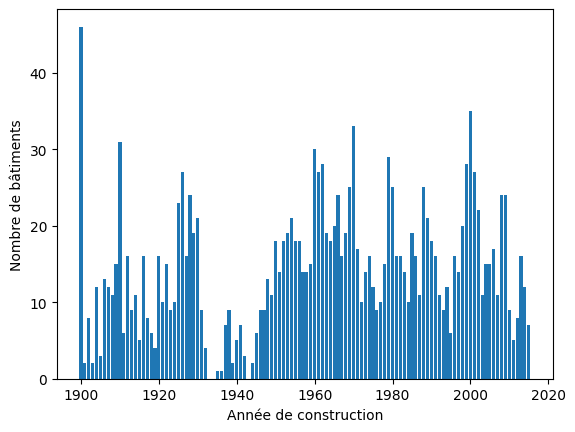

In [ ]:

comptes = df_building_fill['YearBuilt'].value_counts().sort_index()

plt.bar(comptes.index, comptes.values)
plt.xlabel("Année de construction")
plt.ylabel("Nombre de bâtiments")
plt.show()

Avec ce diagramme en barres , je souhaitais verifier que les batiments de la ville ont été construits de maniere espacés et réguliere.  
Ce qui est le cas.  
Pour l'année 1900, il peut y avoir une date par défaut ce qui explique cette valeur elevée.

VISUALISATION DES DONNEES : Batiments Simple-type / Batiments Multi-Type 

Création d'une nouvelle variable a partir d'une existante.   
FE1_Is_multi_type (int64 qui prend 2 valeurs 1 ou 0).   
0 le batiment est mono usage    
1 Le batiment est multi usage.   

In [151]:
# preparation des données pour les afficher en diagramme
# Création de la nouvelle colonne FE1_Is_multi_type 
df_building_fill['FE1_Is_multi_type'] = (
    df_building_fill['ListOfAllPropertyUseTypes']
    .dropna()
    .str.split(',')
    .apply(len)
)

# Transformation des données en 0 et 1 pour faciliter le ML 
df_building_fill['FE1_Is_multi_type'] = df_building_fill['FE1_Is_multi_type'].apply(
    lambda x: 0 if x == 1 else (1 if x >= 2 else x)
)

# Change le type des données de FLOAT en INT (pour eviter les virgules)
df_building_fill['FE1_Is_multi_type'] = df_building_fill['FE1_Is_multi_type'].astype('Int64')


Text(0.5, 1.0, 'Proportion des batiments mono et multi usage')

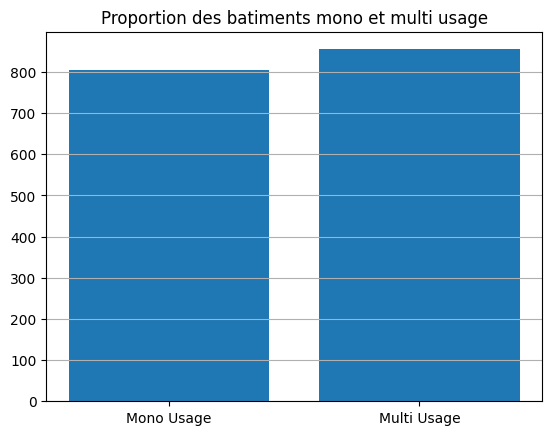

In [152]:
# Diagramme en barres : simple usage / multi usage
comptes_types= df_building_fill['FE1_Is_multi_type'].value_counts()

plt.bar(comptes_types.index, comptes_types.values)
plt.xticks(
    ticks=[0, 1], 
    labels=['Mono Usage', 'Multi Usage'], 
    rotation=0
)
plt.grid(axis='y')
plt.title("Proportion des batiments mono et multi usage")



Avec ce diagramme , nous pouvons constater qu'il y a une proportion presque equivalente des batiments mono-usage et multi-usage

In [29]:
# GRAPH  : surface / consomation d'energie

In [30]:
# GRAPH  : surface / total emissions CO2

#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

# Modélisation 

### Import des modules 

In [ ]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [ ]:
# CODE FEATURE ENGINEERING

### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [ ]:
# CODE PREPARATION DES FEATURES

On peut créer une copie du dataset original (sans les informations inutiles pour ce projet)

In [153]:
# Création du CSV avec le dataset allégé
df_building_fill.to_csv('data/Processed/building_consumption_ready_to_ml.csv')

### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [ ]:
# CODE COMPARAISON DES MODELES

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [ ]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE